#### Tarea 4
## Notebook de métricas de clasificación

### Introducción
La regresión logística es un modelo de Machine Learning supervisado que se utiliza principalmnete para resolver problemas de clasificación, es decir, para predecir a qué categoría pertenece una observación.Es uno de los modelos más utilizados como punto de partida en clasificación porque es relativamente sencillo y rápido.

En el desarrollo de esta tarea se vera un problema de clasificación con regresion logística utilizando el dataset **Bank Marketing**, (Moro et al., 2014) disponible en el UCI Machine Learning Repository. El objetivo del dataset es predecir si un cliente contratará un depósito a plazo fijo, utilizando información demográfica y  financiera. La variable objetivo es `y` que toma los valores `yes` cuando el cliente acepta el depósito y `no` cuando lo rechaza. Se utilizará un modelo de regresión logística para estimar la probabilidad de aceptación y evaluar su utilidad desde una perspectiva tanto estadística como económica.

### Librerias


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

### Dataset

In [18]:
df = pd.read_csv("bank-full.csv", sep=";")

print("Dimensiones del dataset:", df.shape)

display(df.head())

Dimensiones del dataset: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [25]:
df.info()
display(df["y"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


y
no     39922
yes     5289
Name: count, dtype: int64

Se revisó la estructura del conjunto de datos, los tipos de atributos y la distribución de la variable objetivo. Este análisis inicial permite identificar posibles problemas de calidad y determinar si existe un desbalance entre las clases. 

### 1. ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar?

La variable `duration` representa la duración en segundos de la última llamada telefonica. El banco no puede concocer cuánto durará la llamdas antes de realizarla, es por esto que no debe utilizarse, ya que este data solo se conoce después de hacer la llamada y puede generar resultados que no representen de dorma real la capacidad del banco de seleccionar clientes ANTES de llamarlos.

In [26]:
# Eliminamos duration 
df_modelo = df.drop(columns=["duration"])

# Separamos variables predictoras y variable objetivo
X = df_modelo.drop(columns=["y"])

# Convertimos la variable objetivo a valores binarios
y = df_modelo["y"].map({"no": 0, "yes": 1})

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (45211, 15)
Dimensiones de y: (45211,)


### 2. Aparta 20 % de los datos para prueba, con una partición estratificada. ¿Qué exactitud obtiene un clasificador que siempre responde no? ¿Qué dice eso de la exactitud como métrica en este problema?

La partición estratificada permite mantener aproximadamente la misma proporción de clientes que aceptan y rechazan en entrenamiento y prueba.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True))

Entrenamiento: (36168, 15)
Prueba: (9043, 15)

Distribución en entrenamiento:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Distribución en prueba:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


Para un clasificador que siempre predice `no`

In [28]:
# Todas las predicciones no
y_pred_base = np.zeros(len(y_test), dtype=int)

accuracy_base = accuracy_score(y_test, y_pred_base)

print(f"Exactitud del clasificador base: {accuracy_base:.4f}")
print(f"Exactitud porcentual: {accuracy_base * 100:.2f}%")

Exactitud del clasificador base: 0.8830
Exactitud porcentual: 88.30%


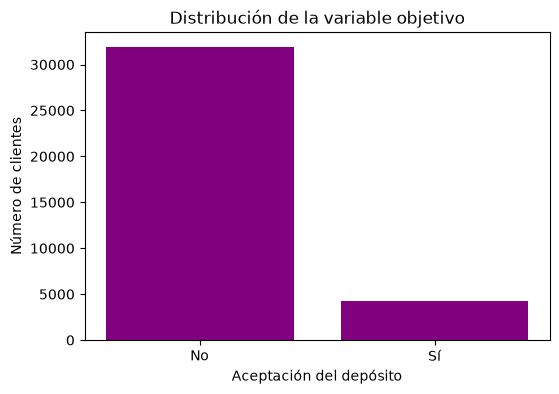

In [12]:
conteo = y_train.value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No", "Sí"], conteo.values, color="purple")

plt.title("Distribución de la variable objetivo")
plt.xlabel("Aceptación del depósito")
plt.ylabel("Número de clientes")

plt.show()

El clasificador que siempre predice `no` obtiene una exactitud aproximada del 88.7 %, debido a que la mayoría de los clientes no acepta el depósito. Esto demuestra que la exactitud puede resultar engañosa en problemas con clases desbalanceadas, ya que un modelo puede alcanzar un porcentaje elevado de aciertos sin realmente hacer nada más que elegir siempre el mismo resultado. 

### 3.  Con un umbral de 0.5, reporta la matriz de confusión, exactitud, precisión, sensibilidad, especificidad y F1. ¿Cuál de esas métricas le importa más al banco, y por qué?

In [30]:
columnas_categoricas = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

columnas_numericas = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Variables categóricas:", columnas_categoricas)
print("Variables numéricas:", columnas_numericas)

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Variables numéricas: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


C:\Users\adria\AppData\Local\Temp\ipykernel_22352\1246553563.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = X_train.select_dtypes(


In [32]:
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), columnas_numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"),
         columnas_categoricas)
    ]
)

modelo = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(max_iter=2000))
])

# Entrenamiento
modelo.fit(X_train, y_train)

# Predicciones
y_pred = modelo.predict(X_test)

# Probabilidades de la clase positiva
y_prob = modelo.predict_proba(X_test)[:, 1]

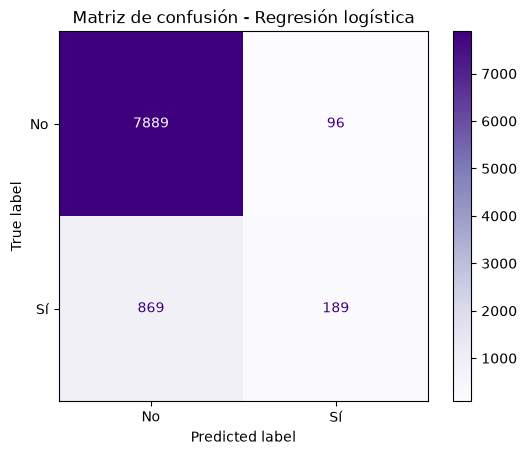

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Sí"],
    cmap="Purples",
    values_format="d"
)

plt.title("Matriz de confusión - Regresión logística")
plt.show()

In [17]:
vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()

exactitud = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
sensibilidad = recall_score(y_test, y_pred, zero_division=0)
especificidad = vn / (vn + fp)
f1 = f1_score(y_test, y_pred, zero_division=0)

metricas = pd.DataFrame({
    "Métrica": [
        "Exactitud",
        "Precisión",
        "Sensibilidad",
        "Especificidad",
        "F1"
    ],
    "Valor": [
        exactitud,
        precision,
        sensibilidad,
        especificidad,
        f1
    ]
})

display(metricas.round(4))

,Métrica,Valor
0,Exactitud,0.8933
1,Precisión,0.6632
2,Sensibilidad,0.1786
3,Especificidad,0.9880
4,F1,0.2815


La matriz de confusión permite evaluar qué tan bien funciona un modelo de clasificación en base a cuatro posible resultados, verdadero positivo, verdadero negativo, falso positivo y falso negativo. Con estos resultados se pueden obtener 5 métricas: (Kavlakoglu, 2026)
1. Exactitud: Proporción de predicciones corerctas respecto al total de observaciones. Un buen porcentaje de exactitud en dataset muy desbalanceado, como lo es este, no significa que el modelo sea bueno. Esto es analogo a lo que se vio anteriomente de que se tenia buen porcentaje cuando el modelo siempre predice `no`
2. Precisión: De las observaciones que se clasificaron como positivas, cuáles realmente lo eran. 
3. Sensibilidad: De todas las observaciones que realmente eran positivas, indica cuántas fueron identificadas correctamente, considea falsos negativos. 
4. Especificidad: De todas las observaciones que realmente eran negativas, indica cuántas fueron identificadas correctamente.
5. F1-score: Permite evaluar el equilibrio entre la presición y la sensibilidad. 

De estas 5 métricas yo me fijaria principalmente en 3: precisión, sensibilidad y F1, ya que permite una evaluación muy completa de un modelo. El banco, en este caso, le importaria más la **presición**, ya que basicamnete indica de los clientes que se decide llamar cuántos aceptan, pudiendo asi ahorrar tiempo en llamadas. EL modelo obtuvo una precisión de 0.66, lo que indica que de 100 clientes marcados como interesados 66 realmente lo eran, lo cual es un porcentaje razonable. 

### 4. Grafica la curva ROC y la curva de precisión contra sensibilidad, con su AUC y su precisión promedio. En scikit-learn, RocCurveDisplay y PrecisionRecallDisplay. ¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?
Las curvas permiten evaluar el comportamiento del modelo con distintos umbrales de clasificación, en lugar de considerar únicamente el umbral de 0.5.

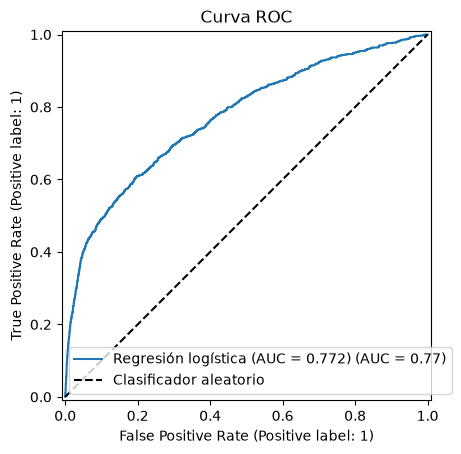

In [47]:
auc_roc = roc_auc_score(y_test, y_prob)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=f"Regresión logística (AUC = {auc_roc:.3f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Clasificador aleatorio")

plt.title("Curva ROC")
plt.legend()
plt.show()

La curva ROC compara la sensibilidad (tasa de verdaderos positivos) contra la tasa de falsos positivos.

c:\Users\adria\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


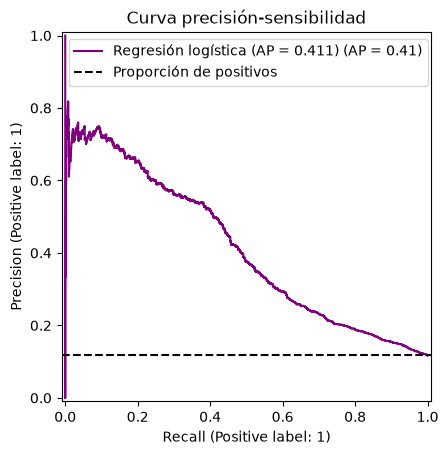

In [45]:
ap = average_precision_score(y_test, y_prob)

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    name=f"Regresión logística (AP = {ap:.3f})",
    color="purple"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="black",
    label="Proporción de positivos"
)

plt.title("Curva precisión-sensibilidad")
plt.legend()
plt.show()

Aquí se utiliza la precisión promedio, que resume la curva precisión-sensibilidad.

In [37]:
print(f"AUC ROC: {auc_roc:.4f}")
print(f"Precisión promedio: {ap:.4f}")
print(f"Proporción de positivos: {y_test.mean():.4f}")

AUC ROC: 0.7717
Precisión promedio: 0.4111
Proporción de positivos: 0.1170


La clase positiva del dataset es minoritaria, lo que provoca que la curva ROC presente un resultado favorable, incluso cuando el modelo genera varios falsos positivos en relación de los con los verdaderos positivos. Es por eso que se decidó jacer la curva de precisión-sensibilidad para ver este problema más claramente, mostrando como cambia la proporción de clientes seleccionados que realmente acepeta el déposito al indentificar más clientes interesados. 

### 5. Cada llamada cuesta 5, acepte o no el cliente, y cada cliente que acepta deja un ingreso de 50. ¿A partir de qué probabilidad conviene llamar? Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.

Considerando un ingreso de 50 por cada cliente que acepta y un costo de 5 por llamada, se  puede calcular facilmente siguiendo un umbral de probabilidad para que convenga llamar:

50p-5>0
50p>5
**p>0.10**

Conviene llamar cuando la probabilidad estimada de aceptación es mayor al 10 %

In [48]:
def calcular_ganancia(y_real, y_predicho):
    llamadas = np.sum(y_predicho == 1)
    aceptaciones = np.sum((y_real == 1) & (y_predicho == 1))

    ingresos = aceptaciones * 50
    costos = llamadas * 5

    return ingresos - costos


# Predicciones con umbral de 0.5
y_pred_05 = (y_prob >= 0.5).astype(int)

# Predicciones con umbral de 0.1
y_pred_01 = (y_prob > 0.1).astype(int)

ganancia_05 = calcular_ganancia(y_test, y_pred_05)
ganancia_01 = calcular_ganancia(y_test, y_pred_01)

comparacion = pd.DataFrame({
    "Umbral": [0.5, 0.1],
    "Llamadas": [
        y_pred_05.sum(),
        y_pred_01.sum()
    ],
    "Aceptaciones": [
        np.sum((y_test == 1) & (y_pred_05 == 1)),
        np.sum((y_test == 1) & (y_pred_01 == 1))
    ],
    "Ganancia total": [
        ganancia_05,
        ganancia_01
    ]
})

display(comparacion)

print(f"Diferencia de ganancia: {ganancia_01 - ganancia_05:.2f}")

,Umbral,Llamadas,Aceptaciones,Ganancia total
0,0.5,285,189,8025
1,0.1,3465,761,20725


Diferencia de ganancia: 12700.00


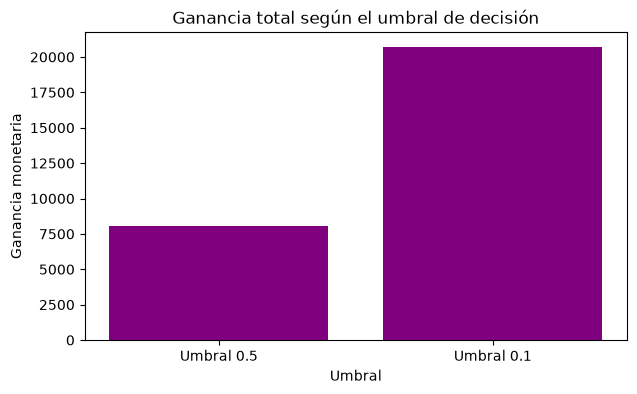

In [51]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Umbral 0.5", "Umbral 0.1"],
    [ganancia_05, ganancia_01],
    color="purple"
)

plt.title("Ganancia total según el umbral de decisión")
plt.ylabel("Ganancia monetaria")
plt.xlabel("Umbral")

plt.show()

Considerando un ingreso de 50 por cada cliente que acepta y un costo de 5 por llamada, el umbral económico es del 10 %, ya que a partir de esta probabilidad el beneficio esperado de llamar se vuelve positivo. En comparación con el umbral tradicional de 0.5, utilizar 0.1 permite contactar a más clientes potenciales, aunque la ganancia real debe evaluarse considerando tanto las contrataciones adicionales como el costo de las llamadas realizadas.

### 6. La variable que quitaste. Repite el punto 3 incluyéndola. ¿Qué les pasa a las métricas? ¿Le servirían al banco?

In [52]:
# Volvemos a introducir duration usando los mismos índices
X_train_duration = df.loc[X_train.index].drop(columns=["y"])
X_test_duration = df.loc[X_test.index].drop(columns=["y"])

# Identificamos tipos de variables
cat_duration = X_train_duration.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_duration = X_train_duration.select_dtypes(
    include=np.number
).columns.tolist()

C:\Users\adria\AppData\Local\Temp\ipykernel_22352\1542842371.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_duration = X_train_duration.select_dtypes(


In [56]:
preprocesador_duration = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), num_duration),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"),
         cat_duration)
    ]
)

modelo_duration = Pipeline(steps=[
    ("preprocesamiento", preprocesador_duration),
    ("clasificador", LogisticRegression(max_iter=2000))
])

modelo_duration.fit(X_train_duration, y_train)

y_pred_duration = modelo_duration.predict(X_test_duration)

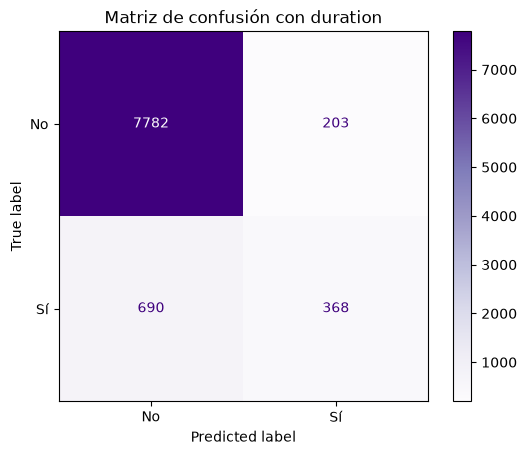

In [58]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_duration,
    display_labels=["No", "Sí"],
    cmap="Purples",
    values_format="d"
)

plt.title("Matriz de confusión con duration")
plt.show()

In [59]:
def obtener_metricas(y_real, y_predicho):
    vn, fp, fn, vp = confusion_matrix(
        y_real, y_predicho
    ).ravel()

    return {
        "Exactitud": accuracy_score(y_real, y_predicho),
        "Precisión": precision_score(
            y_real, y_predicho, zero_division=0
        ),
        "Sensibilidad": recall_score(
            y_real, y_predicho, zero_division=0
        ),
        "Especificidad": vn / (vn + fp),
        "F1": f1_score(
            y_real, y_predicho, zero_division=0
        )
    }


comparacion_metricas = pd.DataFrame({
    "Sin duration": obtener_metricas(y_test, y_pred),
    "Con duration": obtener_metricas(y_test, y_pred_duration)
})

comparacion_metricas["Diferencia"] = (
    comparacion_metricas["Con duration"]
    - comparacion_metricas["Sin duration"]
)

display(comparacion_metricas.round(4))

,Sin duration,Con duration,Diferencia
Exactitud,0.8933,0.9012,0.0080
Precisión,0.6632,0.6445,-0.0187
Sensibilidad,0.1786,0.3478,0.1692
Especificidad,0.9880,0.9746,-0.0134
F1,0.2815,0.4518,0.1704


Al incorporar la variable `duration`, se ve una mejora en las métricas. Como vimos anteriormente esta variable nos dice la duración de la llamdas en minutos, esta infomación esta directamnete relacionada con la probabilidad de contratación, lo que hace que esta variable sea buena para predecir el resultado final. Sin embargo, esta información no es útil para decidir a quién llamar ya que no se tiene de antemano y solamente se puede conseguir después de hacer las llamadas. Incluir esta variable en el modelo puede provocar un rendimiento artificialmente positivo, por lo que es mejor no tomarla en cuenta. 

### Conclusión
La tarea permitio analizar el uso de las métricas para evaluar un modelo de clasificación. En los datasets que hay un desbalance de clases, un clasificador que siempre predice la clase mayoritaria puede obtener una exactitud elevada sin ser realmente útil. Por esta razón, resulta necesario considerar otras métricas, como la precisión, sensibilidad y F1, además de herramientas como las curvas ROC y precisión-sensibilidad.

Por otra parte se demostró que el umbral convencional de 0.5 no necesariamente es el más adecuado para todas las aplicaciones. La elección del umbral debe considerar los costos y beneficios asociados con cada decisión, de manera que las predicciones del modelo puedan realmente aplicarse en su contexto. 

Por último, y considero lo más interesante de la tarea es la la comparación de los modelos con y sin la variable `duration`. Un modelo puede presentar mejores métricas y, aun así, puede ser no aplicable en un escenario real si depende de información que no estará disponible al momento de realizar la predicción. Se puede concluir asi que la calidad de un modelo no debe evaluarse únicamente por sus resultados estadísticos, sino también por su utilidad y viabilidad en el contexto de aplicación

### Bibliografía
Moro, S., Rita, P., & Cortez, P. (2014). A data-driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22–31.

Kavlakoglu, J. M. P. E. (2026, 22 junio). ¿Qué es una matriz de confusión? IBM. https://www.ibm.com/mx-es/think/topics/confusion-matrix
### Declaración de uso de IA
Para el desarrollo de esta práctica se utilizó ChatGPT (OpenAI) como herramienta de apoyo. Los resultados, el código y las interpretaciones obtenidas fueron revisados y ajustados antes de su incorporación a la tarea. 